# Efficient ResNet Challenge: CIFAR-10 (under 5M trainable parameters)

Run the cells top to bottom on a Colab GPU runtime (Runtime > Change runtime type > T4 GPU).

What this notebook does:
1. Trains a custom ResNet from scratch on the 50,000 CIFAR-10 training images only (no pretrained weights, no external data).
2. Prints and asserts the trainable parameter count (must be at most 5,000,000).
3. Loads the hidden test images, with checks so nothing is silently misread, and writes `submission.csv` in the required format.

Nothing about the test file format was given in the competition text, so the test loading section inspects the file first and stops with a clear message if it cannot read it safely.

## 1. Setup

In [17]:
import os, time, math, random, glob, zipfile
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

assert torch.cuda.is_available(), "No GPU found. Use Runtime > Change runtime type > GPU."
device = torch.device("cuda")
torch.backends.cudnn.benchmark = True
print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0))

torch 2.11.0+cu130 | GPU: Tesla T4


## 2. Configuration

All hyperparameters live here, so they can be copied into the report and the GitHub README.

In [18]:
CFG = dict(
    base_width=40,            # channel widths are (w, 2w, 4w, 8w); parameter count is asserted below
    blocks=(2, 2, 2, 2),      # residual blocks per stage
    epochs=100,
    batch_size=128,
    max_lr=0.1,
    weight_decay=5e-4,
    momentum=0.9,
    label_smoothing=0.1,
    pct_warmup=0.15,          # OneCycle warmup fraction
    cutout=8,                 # cutout square size in pixels (0 to disable)
    val_size=5000,            # held-out validation images from the 50k training set
    use_all_data=False,       # set True for the final run to train on all 50k (no validation then)
)
PARAM_LIMIT = 5_000_000
print(CFG)

{'base_width': 40, 'blocks': (2, 2, 2, 2), 'epochs': 100, 'batch_size': 128, 'max_lr': 0.1, 'weight_decay': 0.0005, 'momentum': 0.9, 'label_smoothing': 0.1, 'pct_warmup': 0.15, 'cutout': 8, 'val_size': 5000, 'use_all_data': False}


## 3. Training data (CIFAR-10 train split only)

Only the 50,000 training images are used. The standard 10,000-image CIFAR-10 test split is never loaded, because it may overlap with the hidden evaluation set.

In [19]:
import torchvision
ds = torchvision.datasets.CIFAR10(root="/content/data", train=True, download=True)
X_all = torch.from_numpy(ds.data).permute(0, 3, 1, 2).contiguous()   # N,3,32,32 uint8
y_all = torch.tensor(ds.targets, dtype=torch.long)
assert X_all.shape == (50000, 3, 32, 32), X_all.shape
CLASSES = ds.classes
print(X_all.shape, y_all.shape, CLASSES)

# fixed train/val split
g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(X_all), generator=g)
if CFG["use_all_data"]:
    tr_idx, va_idx = perm, perm[:0]
else:
    va_idx, tr_idx = perm[:CFG["val_size"]], perm[CFG["val_size"]:]
Xtr, ytr = X_all[tr_idx].to(device), y_all[tr_idx].to(device)
Xva, yva = X_all[va_idx].to(device), y_all[va_idx].to(device)

# normalization statistics from the training portion only
MEAN = (Xtr.float() / 255).mean(dim=(0, 2, 3)).view(1, 3, 1, 1)
STD = (Xtr.float() / 255).std(dim=(0, 2, 3)).view(1, 3, 1, 1)
print("train", len(Xtr), "val", len(Xva), "mean", MEAN.flatten().tolist(), "std", STD.flatten().tolist())

def normalize(x_uint8):
    return ((x_uint8.float() / 255) - MEAN) / STD

torch.Size([50000, 3, 32, 32]) torch.Size([50000]) ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
train 45000 val 5000 mean [0.491349995136261, 0.48216143250465393, 0.4465973675251007] std [0.2470489889383316, 0.24355390667915344, 0.2616842985153198]


## 4. GPU data augmentation (random crop with reflect padding, horizontal flip, cutout)

In [20]:
def augment(x_uint8, cutout=8):
    n = x_uint8.size(0)
    x = normalize(x_uint8)
    # random crop: pad 4, then pick a random 32x32 window per image
    p = 4
    xp = F.pad(x, (p, p, p, p), mode="reflect")
    dy = torch.randint(0, 2 * p + 1, (n,), device=x.device)
    dx = torch.randint(0, 2 * p + 1, (n,), device=x.device)
    ar = torch.arange(32, device=x.device)
    iy = (dy[:, None] + ar)[:, None, :, None]
    ix = (dx[:, None] + ar)[:, None, None, :]
    bi = torch.arange(n, device=x.device)[:, None, None, None]
    ci = torch.arange(3, device=x.device)[None, :, None, None]
    x = xp[bi, ci, iy, ix]
    # horizontal flip
    flip = torch.rand(n, device=x.device) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    # cutout
    if cutout > 0:
        cy = torch.randint(0, 32, (n,), device=x.device)
        cx = torch.randint(0, 32, (n,), device=x.device)
        yy = ar[None, :, None]; xx = ar[None, None, :]
        m = ((yy - cy[:, None, None]).abs() <= cutout // 2) & ((xx - cx[:, None, None]).abs() <= cutout // 2)
        x = x * (~m)[:, None, :, :].float()
    return x.contiguous(memory_format=torch.channels_last)

## 5. Model

A CIFAR-style ResNet: 3x3 stem, four stages of BasicBlocks with identity skips (1x1 conv projection skips where the shape changes), global average pooling and a linear head. The parameter count is asserted against the 5M limit.

In [21]:
class BasicBlock(nn.Module):
    def __init__(self, cin, cout, stride):
        super().__init__()
        self.c1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.b1 = nn.BatchNorm2d(cout)
        self.c2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False);     self.b2 = nn.BatchNorm2d(cout)
        self.skip = None
        if stride != 1 or cin != cout:
            self.skip = nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))
    def forward(self, x):
        out = F.relu(self.b1(self.c1(x)), inplace=True)
        out = self.b2(self.c2(out))
        return F.relu(out + (x if self.skip is None else self.skip(x)), inplace=True)

class ResNet(nn.Module):
    def __init__(self, base=40, blocks=(2, 2, 2, 2), num_classes=10):
        super().__init__()
        widths = [base, base * 2, base * 4, base * 8]
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, 1, 1, bias=False), nn.BatchNorm2d(widths[0]), nn.ReLU(inplace=True))
        layers, cin = [], widths[0]
        for i, (w, nb) in enumerate(zip(widths, blocks)):
            for j in range(nb):
                layers.append(BasicBlock(cin, w, stride=(2 if (j == 0 and i > 0) else 1)))
                cin = w
        self.layers = nn.Sequential(*layers)
        self.fc = nn.Linear(cin, num_classes)
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
    def forward(self, x):
        x = self.layers(self.stem(x))
        return self.fc(F.adaptive_avg_pool2d(x, 1).flatten(1))

def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

model = ResNet(CFG["base_width"], CFG["blocks"]).to(device).to(memory_format=torch.channels_last)
n_params = count_params(model)
print(f"Trainable parameters: {n_params:,} (limit {PARAM_LIMIT:,})")
assert n_params <= PARAM_LIMIT, "Over the 5M parameter limit. Lower CFG['base_width']."

Trainable parameters: 4,368,690 (limit 5,000,000)


## 6. Training

In [22]:
@torch.no_grad()
def evaluate(model, X, y, bs=1000):
    model.eval(); correct = 0
    for i in range(0, len(X), bs):
        xb = normalize(X[i:i+bs]).contiguous(memory_format=torch.channels_last)
        with torch.autocast("cuda", dtype=torch.float16):
            correct += (model(xb).argmax(1) == y[i:i+bs]).sum().item()
    return correct / max(len(X), 1)

decay, no_decay = [], []
for n_, p_ in model.named_parameters():
    (no_decay if p_.ndim <= 1 else decay).append(p_)
opt = torch.optim.SGD([{"params": decay, "weight_decay": CFG["weight_decay"]},
                       {"params": no_decay, "weight_decay": 0.0}],
                      lr=CFG["max_lr"], momentum=CFG["momentum"], nesterov=True)
steps_per_epoch = math.ceil(len(Xtr) / CFG["batch_size"])
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG["max_lr"], epochs=CFG["epochs"],
                                            steps_per_epoch=steps_per_epoch, pct_start=CFG["pct_warmup"],
                                            anneal_strategy="cos", div_factor=25, final_div_factor=1e3)
scaler = torch.cuda.amp.GradScaler()
crit = nn.CrossEntropyLoss(label_smoothing=CFG["label_smoothing"])

history = []
t0 = time.time()
for epoch in range(CFG["epochs"]):
    model.train()
    perm = torch.randperm(len(Xtr), device=device)
    run_loss, seen = 0.0, 0
    for i in range(0, len(Xtr), CFG["batch_size"]):
        idx = perm[i:i + CFG["batch_size"]]
        xb, yb = augment(Xtr[idx], CFG["cutout"]), ytr[idx]
        with torch.autocast("cuda", dtype=torch.float16):
            loss = crit(model(xb), yb)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(opt); scaler.update(); sched.step()
        run_loss += loss.item() * len(idx); seen += len(idx)
    va = evaluate(model, Xva, yva) if len(Xva) else float("nan")
    history.append((epoch + 1, run_loss / seen, va))
    if (epoch + 1) % 5 == 0 or epoch == 0 or epoch + 1 == CFG["epochs"]:
        print(f"epoch {epoch+1:3d}/{CFG['epochs']} | train loss {run_loss/seen:.4f} | val acc {va:.4f} | {time.time()-t0:.0f}s")

torch.save(model.state_dict(), "/content/resnet_final.pt")
print("Final val acc:", history[-1][2], "| params:", count_params(model))

/tmp/ipykernel_2962/279805051.py:20: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


epoch   1/100 | train loss 1.8106 | val acc 0.5166 | 12s
epoch   5/100 | train loss 1.1560 | val acc 0.7262 | 51s
epoch  10/100 | train loss 0.9571 | val acc 0.7690 | 98s
epoch  15/100 | train loss 0.8662 | val acc 0.7840 | 145s
epoch  20/100 | train loss 0.8175 | val acc 0.8114 | 193s
epoch  25/100 | train loss 0.7926 | val acc 0.8572 | 240s
epoch  30/100 | train loss 0.7748 | val acc 0.8814 | 288s
epoch  35/100 | train loss 0.7556 | val acc 0.8664 | 335s
epoch  40/100 | train loss 0.7405 | val acc 0.8702 | 382s
epoch  45/100 | train loss 0.7298 | val acc 0.8694 | 430s
epoch  50/100 | train loss 0.7195 | val acc 0.8956 | 477s
epoch  55/100 | train loss 0.7044 | val acc 0.8806 | 525s
epoch  60/100 | train loss 0.6898 | val acc 0.9052 | 572s
epoch  65/100 | train loss 0.6755 | val acc 0.9028 | 619s
epoch  70/100 | train loss 0.6536 | val acc 0.9136 | 667s
epoch  75/100 | train loss 0.6286 | val acc 0.9140 | 714s
epoch  80/100 | train loss 0.6020 | val acc 0.9284 | 761s
epoch  85/100 | t

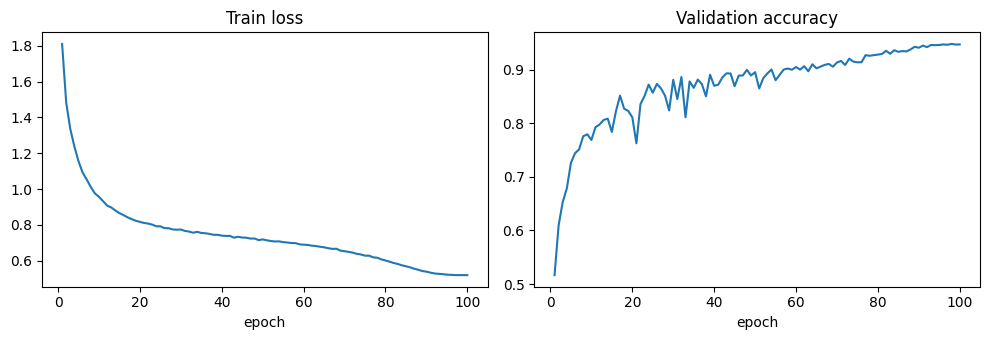

In [23]:
# optional: loss / accuracy curves
import matplotlib.pyplot as plt
ep = [h[0] for h in history]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(ep, [h[1] for h in history]); ax[0].set_title("Train loss"); ax[0].set_xlabel("epoch")
ax[1].plot(ep, [h[2] for h in history]); ax[1].set_title("Validation accuracy"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

## 7. Locate the test files

Upload the competition files to Colab (left sidebar > Files), or mount Google Drive. Then run this cell to see everything that is there. Set `TEST_PATH` and `SAMPLE_SUB` in the next cell from what it shows.

In [24]:
for root in ["/content"]:
    for p in sorted(glob.glob(root + "/*")):
        if os.path.basename(p) in ("data", "sample_data"):
            continue
        print(p, "(dir)" if os.path.isdir(p) else f"({os.path.getsize(p)/1e6:.2f} MB)")

/content/resnet_final.pt (17.54 MB)


In [30]:
# EDIT THESE two paths using the listing above
SAMPLE_SUB = "/content/sample_submission.csv"   # your file may be named "sample_submission 2.csv"
TEST_PATH  = "/content/test_data"               # file (.npy/.npz/.pkl/.csv/.zip) or folder of images

In [31]:
import pandas as pd, numpy as np
for name in ["test_data.csv", "train_labels.csv"]:
    p = f"/content/{name}"
    df = pd.read_csv(p)
    print("=====", name, df.shape)
    print("first columns:", list(df.columns[:6]), "... last:", list(df.columns[-3:]))
    print("dtypes:", df.dtypes.value_counts().to_dict())
    print(df.iloc[:3, :8])
    if df.shape[1] > 2:
        v = df.select_dtypes("number").drop(columns=[c for c in df.columns if c.lower()=="id"], errors="ignore").values
        print("pixel-like min/max:", v.min(), v.max())

tl = pd.read_csv("/content/train_labels.csv")
print("\ntrain_labels label counts:\n", tl.iloc[:, -1].value_counts().sort_index().to_dict())
print("matches torchvision train labels (same order)?",
      len(tl) == len(y_all) and (tl.iloc[:, -1].values == y_all.numpy()).all())

FileNotFoundError: [Errno 2] No such file or directory: '/content/test_data.csv'

## 8. Load the test images with safety checks

Supported: a folder of images (ids taken from the numeric file names), `.npy`, `.npz`, `.pkl`, a `.csv` with an `id` column plus 3072 pixel columns, or a `.zip` of images. If the file is something else, the cell stops with a message instead of guessing.

In [28]:
import pandas as pd, pickle
from PIL import Image

sub = pd.read_csv(SAMPLE_SUB)
assert list(sub.columns) == ["id", "label"], sub.columns
print("sample_submission rows:", len(sub), "| id range:", sub["id"].min(), "to", sub["id"].max())

def to_nchw_uint8(arr):
    arr = np.asarray(arr)
    if arr.dtype != np.uint8:
        if np.issubdtype(arr.dtype, np.floating) and arr.min() >= 0 and arr.max() <= 1.0:
            arr = (arr * 255).round().astype(np.uint8)
        elif np.issubdtype(arr.dtype, np.floating) or np.issubdtype(arr.dtype, np.integer):
            if arr.min() >= 0 and arr.max() <= 255:
                arr = arr.astype(np.uint8)
            else:
                raise ValueError(f"Pixel values out of 0..255 range: min {arr.min()}, max {arr.max()}. Tell me the preprocessing used.")
        else:
            raise ValueError(f"Unsupported dtype {arr.dtype}")
    if arr.ndim == 2 and arr.shape[1] == 3072:
        print("WARNING: flat 3072 vectors reshaped as channel-first (3,32,32), the original CIFAR layout. Check the preview below.")
        arr = arr.reshape(-1, 3, 32, 32)
    elif arr.ndim == 4 and arr.shape[1:] == (32, 32, 3):
        arr = arr.transpose(0, 3, 1, 2)
    elif arr.ndim == 4 and arr.shape[1:] == (3, 32, 32):
        pass
    else:
        raise ValueError(f"Unexpected array shape {arr.shape}")
    return np.ascontiguousarray(arr)

def load_image_dir(d):
    files = [f for f in glob.glob(os.path.join(d, "**", "*"), recursive=True)
             if f.lower().endswith((".png", ".jpg", ".jpeg", ".bmp"))]
    assert files, f"No image files found under {d}"
    keyed = []
    for f in files:
        stem = os.path.splitext(os.path.basename(f))[0]
        assert stem.isdigit(), f"File name {os.path.basename(f)} is not a numeric id, cannot map to submission ids."
        keyed.append((int(stem), f))
    keyed.sort()
    ids = np.array([k for k, _ in keyed])
    imgs = np.stack([np.array(Image.open(f).convert("RGB")) for _, f in keyed])
    return ids, imgs

def load_test(path):
    ids = None
    if os.path.isdir(path):
        ids, arr = load_image_dir(path)
    else:
        ext = os.path.splitext(path)[1].lower()
        if ext == ".zip":
            out = "/content/test_extracted"
            with zipfile.ZipFile(path) as z: z.extractall(out)
            ids, arr = load_image_dir(out)
        elif ext == ".npy":
            arr = np.load(path, allow_pickle=False)
        elif ext == ".npz":
            z = np.load(path, allow_pickle=False)
            print("npz keys:", list(z.keys()))
            assert len(z.keys()) == 1, "Several arrays in the npz. Set the key you want explicitly."
            arr = z[list(z.keys())[0]]
        elif ext in (".pkl", ".pickle"):
            with open(path, "rb") as f: obj = pickle.load(f)
            if isinstance(obj, dict):
                print("pickle keys:", list(obj.keys()))
                key = [k for k in obj if k in ("data", "images", "x", "X", b"data")]
                assert len(key) == 1, "Cannot tell which key holds the images. Tell me the key."
                if "id" in obj or "ids" in obj: ids = np.asarray(obj.get("id", obj.get("ids")))
                arr = obj[key[0]]
            else:
                arr = obj
        elif ext == ".csv":
            df = pd.read_csv(path)
            assert "id" in df.columns and df.shape[1] == 3073, f"CSV columns not as expected: {df.shape}"
            ids = df["id"].values
            arr = df.drop(columns=["id"]).values
        else:
            raise ValueError(f"Unrecognised test format: {path}")
    return ids, to_nchw_uint8(arr)

test_ids, Xte = load_test(TEST_PATH)
print("test array:", Xte.shape, Xte.dtype, "| min", Xte.min(), "max", Xte.max())
assert len(Xte) == len(sub), f"Test has {len(Xte)} images but sample_submission has {len(sub)} rows."
if test_ids is None:
    print("WARNING: the test file has no ids, so row order is assumed to match sample_submission order.")
    test_ids = sub["id"].values
assert set(test_ids.tolist()) == set(sub["id"].tolist()), "Test ids do not match sample_submission ids."
Xte_t = torch.from_numpy(Xte).to(device)

sample_submission rows: 2000 | id range: 0 to 1999


ValueError: Unrecognised test format: /content/test_data

## 9. Predict (with horizontal-flip test-time augmentation) and write submission.csv

In [ ]:
@torch.no_grad()
def predict(model, X, bs=500):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        xb = normalize(X[i:i+bs]).contiguous(memory_format=torch.channels_last)
        with torch.autocast("cuda", dtype=torch.float16):
            lo = model(xb).float().softmax(1) + model(xb.flip(3)).float().softmax(1)
        out.append(lo.cpu())
    return torch.cat(out)

# sanity check: flip-TTA on the validation split vs plain
if len(Xva):
    pv = predict(model, Xva).argmax(1)
    print("Val acc with flip TTA:", (pv.to(device) == yva).float().mean().item(), "| plain:", evaluate(model, Xva, yva))

probs = predict(model, Xte_t)
pred = probs.argmax(1).numpy()

out = pd.DataFrame({"id": test_ids, "label": pred.astype(int)})
out = out.set_index("id").loc[sub["id"].values].reset_index()      # same order as sample_submission
out.to_csv("/content/submission.csv", index=False)

chk = pd.read_csv("/content/submission.csv")
assert list(chk.columns) == ["id", "label"] and len(chk) == len(sub)
assert (chk["id"].values == sub["id"].values).all() and chk["label"].between(0, 9).all()
print("submission.csv OK:", chk.shape); print(chk.head()); print(chk["label"].value_counts().sort_index().to_dict())

## 10. Visual check of the test loading

If the predicted class names clearly do not match the pictures (for example every picture looks like noise or colours look wrong), the test format was misread. Do not submit in that case, tell me the file format and I will adjust the loader.

In [ ]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(2, 8, figsize=(16, 4.4))
for a, i in zip(axs.flat, range(16)):
    a.imshow(Xte[i].transpose(1, 2, 0)); a.set_title(CLASSES[pred[i]], fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
from google.colab import files
files.download("/content/submission.csv")